# QubitYield: The Calibration Contract

A reproducible investigation of Challenge 4. All case data are fictional and all quantum results are simulated. See `docs/ai-assistance.md` for disclosure.

## 1. Investigate

Working hypothesis: automate calibration first because eight hours/day looks like the largest loss. Falsifiers: recovered windows have no unmet demand, or pulse improvement produces greater validated application value. The experiment tests baseline, AI calibration, pulse optimization and cheaper controls.

In [1]:
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data' / 'case_facts.json').exists())
sys.path.insert(0, str(root / 'src'))
from qubityield.models import Scenario
from qubityield.analysis import evaluate
from qubityield.quantum import compare_benchmarks
scenario = Scenario.model_validate({'calibration_hours': 8.0, 'booking_utilization': 0.7, 'already_automated': 0.35, 'ai_speed_claim': 0.7, 'ai_speed_interpretation': 'rate_increase', 'scale_realization': 0.7, 'monetizable_overlap': 0.25, 'demand_hours_per_day': 11.2, 'value_per_productive_hour': 1000.0, 'value_realization': 0.35, 'value_mode': 'additional_output', 'operating_days': 365, 'discount_rate': 0.12, 'contract_years': 3, 'contract_total': 5000000.0, 'rollout_months': 6.0, 'replacement_due': False, 'control_cost': 2000000.0, 'control_saving': 0.3, 'control_engineers': 3, 'control_integration_months': 6.0, 'engineer_annual_cost': 300000.0, 'n_qubits': 20, 'layers': 20, 'shots': 8192, 'seed': 7, 'baseline_gate_error': 0.01, 'pulse_gate_error': 0.005, 'baseline_gate_ns': 300.0, 'pulse_duration_increase': 0.4, 'fixed_overhead_us': 100.0, 't1_us': 120.0, 't2_us': 120.0, 'noise_mode': 'reported_total', 'readout_error': 0.0})
result = evaluate(scenario)
result['evidence']

{'experiment_id': 'qy-bf831cab2db1',
 'seed': 7,
 'shots': 8192,
 'source': 'simulated',
 'generated_at': '2026-11-22T10:50:35+00:00',
 'model_version': '0.2.0',
 'source_code_sha256': 'fa2131f3fe08a1d21bf094ffd8ea31a40e2aca5e3c7a9068c801877a457d56f4',
 'case_facts_sha256': '824b84f8be39c5f7f6de13878cf22b5fe41f5f6bc86aad1fd83a1d7da45ed745',
 'physical_fingerprint': '6152176dc522828b4040a8c6170a0a30f68f1b3f7c04110c472602498b1c723f',
 'scenario_sha256': 'bf831cab2db1c993f67029addeabbb302baf9b0f136cd1d3809e779c72df9ca1',
 'versions': {'numpy': '2.5.5', 'scipy': '1.18.1', 'pydantic': '2.14.4'},
 'backend': 'NumPy Pauli-frame Clifford simulator',
 'hardware_executed': False,
 'uncertainty_scope': 'Shot intervals are conditional on the selected circuit and noise model. Commercial ranges are assumptions, not calibrated probabilities.'}

## 2. Experiment

The 20-qubit Clifford mirror uses 200 CX gates in 20 parallel layers. The known ideal output is all zero. The NumPy engine propagates actual Pauli faults; a separate Qiskit Aer adapter checks it independently. The default error is interpreted as total average gate infidelity. Coherence is not counted twice.

Per-circuit intervals describe sampling error only. They do not quantify business uncertainty.

In [2]:
import pandas as pd
pd.DataFrame([{
    'proposal': name, 'successes': result['benchmark'][name]['successes'],
    'shots': result['benchmark'][name]['shots'],
    'return_probability': result['benchmark'][name]['p_success'],
    'CI_low': result['benchmark'][name]['ci_low'], 'CI_high': result['benchmark'][name]['ci_high'],
} for name in ['baseline', 'pulse']])

,proposal,successes,shots,return_probability,CI_low,CI_high
0,baseline,772,8192,0.094238,0.088100,0.100756
1,pulse,2468,8192,0.301270,0.291429,0.311296


In [3]:
columns = ['label', 'booked_hours_day', 'incremental_useful_hours_year', 'annual_benefit_usd', 'customer_npv_usd']
pd.DataFrame(result['options'])[columns]

,label,booked_hours_day,incremental_useful_hours_year,annual_benefit_usd,customer_npv_usd
0,Keep current system,11.2,0.000000,0.000000e+00,0.000000e+00
1,AI calibration,11.2,0.000000,0.000000e+00,-4.003052e+06
2,Pulse optimization,11.2,8691.543047,3.042040e+06,1.945361e+06
3,Lower-cost controls,11.2,0.000000,0.000000e+00,-4.453052e+06


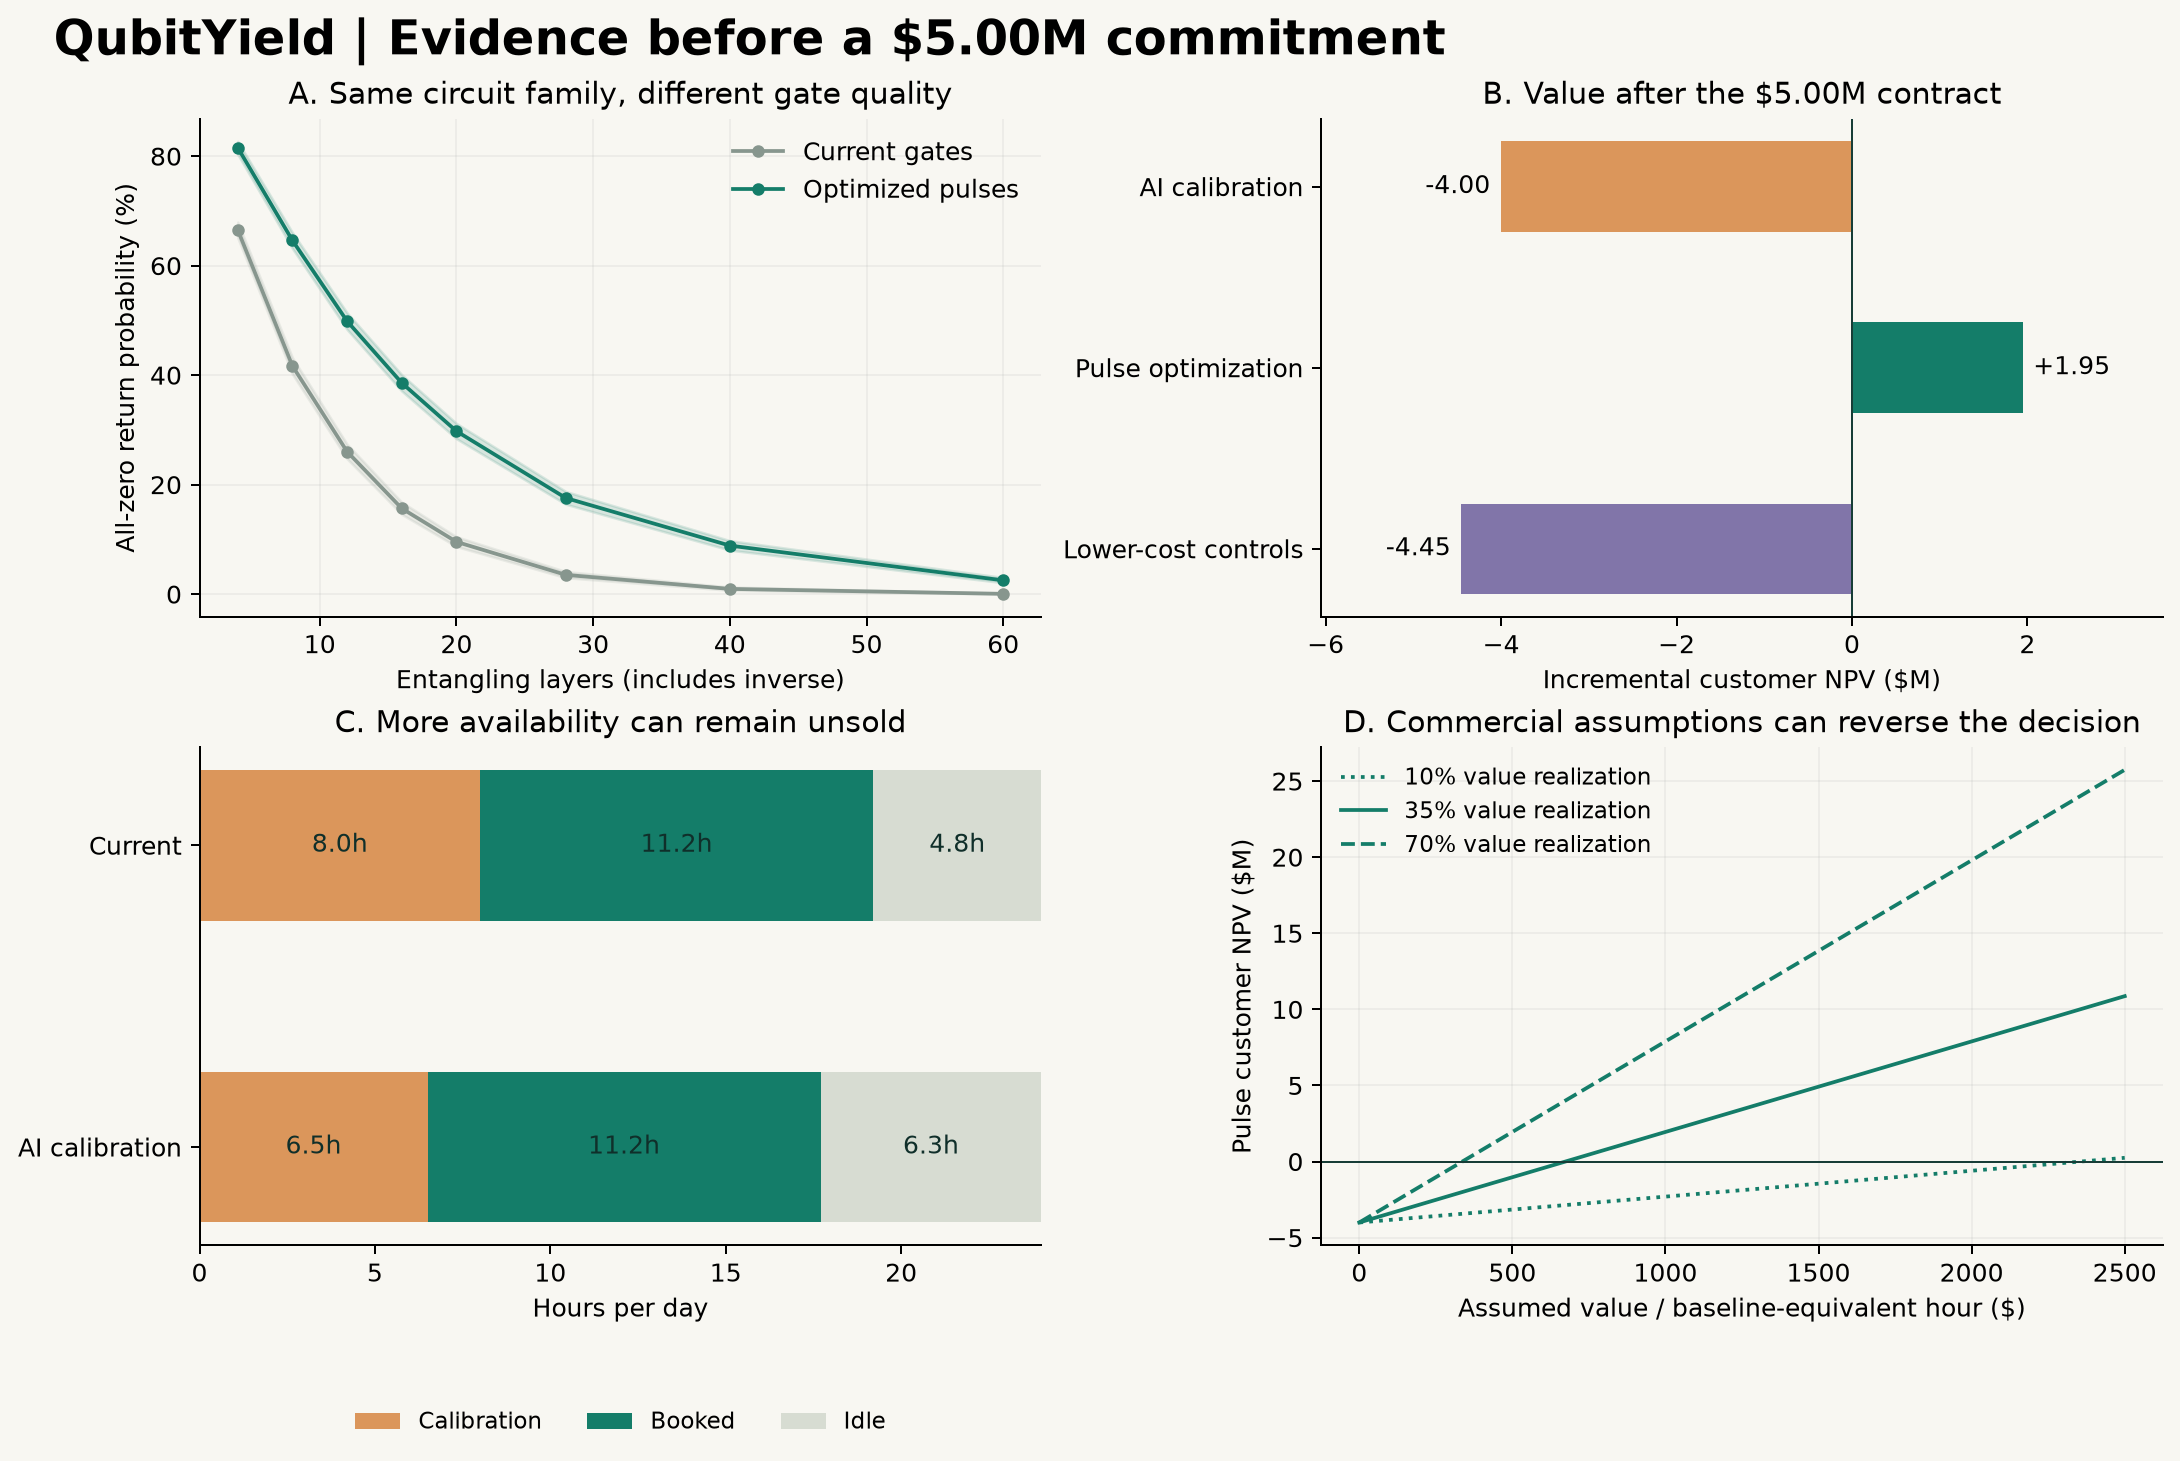

In [4]:
from IPython.display import Image, display
from tempfile import TemporaryDirectory
from qubityield.reporting import plot_decision
# Render this notebook's own evidence, including when reports use a custom output folder.
with TemporaryDirectory(prefix='qubityield-notebook-') as directory:
    figure_path = Path(directory) / 'decision_landscape.png'
    plot_decision(result, figure_path)
    display(Image(filename=str(figure_path)))

## Sensitivity and the strongest counter-case

Dollar value and commercial realization are unvalidated assumptions. Lower either enough and the proposed deal stops being worthwhile. Valuing more output also differs from saving runtime for the same output. New availability alone cannot generate demand.

In [5]:
low_value = scenario.model_copy(update={'value_per_productive_hour': 250, 'value_realization': 0.10})
low_result = evaluate(low_value, include_depth=False)
{'default_verdict': result['recommendation']['contract_verdict'], 'low_value_verdict': low_result['recommendation']['contract_verdict'], 'low_value_options': [{k: o[k] for k in ('label', 'customer_npv_usd')} for o in low_result['options']]}

{'default_verdict': 'Conditional go after validation',
 'low_value_verdict': 'Renegotiate',
 'low_value_options': [{'label': 'Keep current system',
   'customer_npv_usd': 0.0},
  {'label': 'AI calibration', 'customer_npv_usd': -4003052.113702623},
  {'label': 'Pulse optimization', 'customer_npv_usd': -3578165.445855791},
  {'label': 'Lower-cost controls', 'customer_npv_usd': -4453052.113702623}]}

In [6]:
same_work = scenario.model_copy(update={'value_mode': 'fixed_output_savings'})
savings_result = evaluate(same_work, include_depth=False)
pd.DataFrame([{'valuation': label, **next(o for o in item['options'] if o['id'] == 'pulse')} for label, item in [('Additional useful output', result), ('Same useful output, less runtime', savings_result)]])[['valuation', 'annual_benefit_usd', 'customer_npv_usd', 'price_ceiling_usd']]

,valuation,annual_benefit_usd,customer_npv_usd,price_ceiling_usd
0,Additional useful output,3.042040e+06,1.945361e+06,7.429848e+06
1,"Same useful output, less runtime",9.731068e+05,-2.100237e+06,2.376706e+06


In [7]:
# Five predeclared circuit seeds test circuit dependence. No best-seed selection.
robustness = compare_benchmarks(seeds=(7,17,29,43,71), shots=scenario.shots, noise_mode=scenario.noise_mode)
{arm: {k: v for k, v in robustness[arm].items() if k != 'runs'} for arm in ('baseline','optimized')}

{'baseline': {'mean_success': 0.091552734375,
  'min_success': 0.08447265625,
  'max_success': 0.0977783203125,
  'circuit_standard_deviation': 0.00568446726165774,
  'total_shots': 40960,
  'total_successes': 3750},
 'optimized': {'mean_success': 0.3026123046875,
  'min_success': 0.2918701171875,
  'max_success': 0.32080078125,
  'circuit_standard_deviation': 0.012092664941022057,
  'total_shots': 40960,
  'total_successes': 12395}}

## Commercial stress and pricing

A regular grid describes the stated assumption combinations. Its win coverage is not a probability of commercial success. Vendor costs are explicit illustrative assumptions. Pricing checks both nominal margin and discounted cash-flow break-even, using the same payment schedule as the customer's ceiling.

In [8]:
from qubityield.decision_tools import StressRequest, PricingRequest, evaluate_stress, evaluate_pricing
stress = evaluate_stress(StressRequest(scenario=scenario), result['benchmark'])
pd.DataFrame(stress['options'])[['label', 'worst_npv_usd', 'base_npv_usd', 'best_npv_usd', 'win_coverage', 'max_regret_usd']]

,label,worst_npv_usd,base_npv_usd,best_npv_usd,win_coverage,max_regret_usd
0,Keep current system,0.000000e+00,0.000000e+00,0.000000e+00,0.368,2.309137e+07
1,AI calibration,-5.604273e+06,-4.003052e+06,-2.401831e+06,0.000,2.549320e+07
2,Pulse optimization,-5.179386e+06,1.945361e+06,2.309137e+07,0.632,5.179386e+06
3,Lower-cost controls,-6.054273e+06,-4.453052e+06,-2.851831e+06,0.000,2.594320e+07


In [9]:
pricing = evaluate_pricing(PricingRequest(scenario=scenario), result['benchmark'])
pd.DataFrame(pricing['options'])[['label', 'customer_zero_npv_cap_usd', 'vendor_floor_usd', 'customer_share_target_usd', 'share_policy_feasible', 'status_label']]

,label,customer_zero_npv_cap_usd,vendor_floor_usd,customer_share_target_usd,share_policy_feasible,status_label
0,AI calibration,0.000000e+00,2375000.0,0.000000e+00,False,No positive customer-supported contract price
1,Pulse optimization,7.429848e+06,2375000.0,2.228954e+06,False,Value-share target is below the vendor floor
2,Lower-cost controls,0.000000e+00,2375000.0,0.000000e+00,False,No positive customer-supported contract price


In [10]:
# The selected share is a negotiation assumption, not a market fact.
negotiated = evaluate_pricing(PricingRequest(scenario=scenario, customer_value_share=0.35), result['benchmark'])
{'nominal_margin_floor': pricing['nominal_margin_floor_usd'], 'discounted_cash_floor': pricing['discounted_break_even_floor_usd'], 'default_policy': pricing['recommendation'], 'alternative_share_policy': negotiated['recommendation']}

{'nominal_margin_floor': 2375000.0,
 'discounted_cash_floor': 1074523.4708392604,
 'default_policy': {'option_id': 'pulse',
  'deal_feasible': False,
  'summary': 'Pulse optimization has potential joint surplus, but the selected share of customer value is below the vendor floor. Raise the negotiated share or reduce delivery cost; no price is recommended under the current policy.'},
 'alternative_share_policy': {'option_id': 'pulse',
  'deal_feasible': True,
  'summary': 'Pulse optimization admits a price that meets the assumed vendor margin, cash-flow break-even and selected value-share policy. Validate the costs and customer benefit before treating that range as an offer.'}}

## 3. Recommend

Prioritize pulse validation; the initial calibration-first hypothesis does not survive the stated demand. Validate matched-wall-clock customer application outcomes before committing the full contract. The price ceiling is a scenario-dependent zero-NPV bound, not a quote. See `artifacts/decision_memo.pdf` for the executive recommendation and `docs/pilot-plan.md` for the experiment gates.

## Reproduce and audit

Run `qubityield reproduce`, `pytest`, and `python scripts/validate_qiskit.py`. Case inputs, assumptions, source references, simulation counts, and code are all included. No claims of quantum advantage or real hardware measurements are made.